# YOLOv11 Retraining & ONNX Export Pipeline

This notebook downloads custom Roboflow dataset (`smart_cooling_edge_ai`), fine-tunes the **YOLOv11** student detection model for 100 epochs, evaluates performance, and automatically exports the final model to **`models/yolo11n.onnx`**.

## Install Dependencies & Download Dataset from Roboflow

In [ ]:
!pip install -q ultralytics roboflow onnx onnxruntime

from roboflow import Roboflow
rf = Roboflow(api_key="your-roboflow-apikey")
project = rf.workspace("your-workspace").project("your_project_name")
dataset = project.version(1).download("yolov11")

# Train YOLOv11n Model

Before training,

* Ensure you have the Installed necessary dependencies, including `ultralytics` and `roboflow`.
* Ensure your PC has a GPU with CUDA support for faster training. If not, you can still train on CPU, but it will be significantly slower. And also, make sure you have enough RAM and disk space to handle the dataset and model files. 
* Ensure you have the necessary permissions to access the Roboflow dataset. You may need to sign up for a Roboflow account and obtain an API key to download the dataset.
* Ensure you have pytorch installed with the correct version that is compatible with your GPU and CUDA version. You can check the compatibility matrix on the PyTorch website.
* Othrerwise, you can use Google Colab or Kaggle for free GPU access.

# MLflow Experiment Tracking & Optuna Hyperparameter Tuning

In [12]:
import os
from ultralytics import YOLO
from ultralytics.utils import SETTINGS
import torch

# Disable Ultralytics auto-logging conflict
SETTINGS.update({"mlflow": False})

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [13]:
# Check is GPU available for training.
device = 0 if torch.cuda.is_available() else 'cpu'
print(f"Training device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

Training device: 0 (NVIDIA GeForce GTX 1650)


In [14]:
import mlflow
import optuna
import shutil

#MLflow Tracker Initialization

In [15]:
# Initialize Mlflow tracking with SQLite backend
mlflow_db_uri = "sqlite:///mlflow.db"
mlflow.set_tracking_uri(mlflow_db_uri)

## Initializing the YOLOv11n Hyperparameters

In [16]:
# Initialize hyperparameters helper - optuna trail
def hyperparameters(trial):
    return{
        "lr0": trial.suggest_float("lr0",1e-4 , 1e-2,log=True ),
        "lrf": trial.suggest_float("lrf", 0.01, 0.2),
        "momentum": trial.suggest_float("momentum", 0.85, 0.98),
        "weight_decay": trial.suggest_float("weight_decay", 1e-5, 1e-3, log=True),
        "box": trial.suggest_float("box", 5.0,10.0),
        "cls": trial.suggest_float("cls", 0.3,1.5),
        "hsv_h": trial.suggest_float("hsv_h", 0.0,0.05),
        "hsv_s": trial.suggest_float("hsv_s", 0.2,0.8),
        "hsv_v": trial.suggest_float("hsv_v", 0.2,0.6)
    }

In [17]:
# Initialize mlflow logger
def log_trial_artifacts(params, trial_num, results):
    mlflow.log_params(params)
    mlflow.log_param("trial_number", trial_num)

    mlflow.log_metrics({
        "mAP50": results.box.map50,
        "mAP50_95": results.box.map,
        "precision": results.box.mp,
        "recall": results.box.mr
    })

    # log plots
    save_dir = results.save_dir
    plot_files =["confusion_matrix.png", "F1_curve.png", "PR_curve.png", "results.png"]

    for plot_file in plot_files:
        plot_path = os.path.join(save_dir, plot_file)
        if os.path.exists(plot_path):
            mlflow.log_artifact(plot_path, artifact_path="plots")

    # log best model weights
    best_weight_path = os.path.join(save_dir, "weights", "best.pt")
    if os.path.exists(best_weight_path):
        mlflow.log_artifact(best_weight_path, artifact_path="weights")

In [18]:
# Locate data.yaml inside downloaded dataset
dataset_yaml = "./smart_cooling_edge_ai-1/data.yaml"
print(f"Dataset location: {dataset_yaml}")

Dataset location: ./smart_cooling_edge_ai-1/data.yaml


In [ ]:
import gc 

runs_dir = os.path.abspath("hpo_experiments/HPO_Trials")

def objective(trial):

    # GPU vram memory cleanup
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    params = hyperparameters(trial) # sample hps
    run_name = f"Trial_{trial.number}_lr_{params['lr0']:.4f}"

    with mlflow.start_run(run_name=run_name, nested=True):
        model = YOLO("yolo11n.pt")

        results = model.train(
            data=dataset_yaml,
            epochs=30, # why use 30 epochs - we can identify what hyperparams in relative comparison in 20-30 epochs in per Trail. no need 100-300 
            imgsz=640,
            batch=8,
            workers=4,
            project=runs_dir, 
            name=f"optuna_trial_{trial.number}",
            plots=True,
            exist_ok=True,
            verbose=False,
            **params
        )

        # log mlflow using logger
        log_trial_artifacts(params, trial.number, results)

        # GPU vram memory cleanup
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        return float(results.box.map50) # return mAP50 float score to Optuna


## Hyperparameter Tunning

In [20]:

# set Optuna study become mAP50 score -maximize
study = optuna.create_study(direction="maximize", study_name="yolo11_hpo_study")

# run 5 trials
n_trials = 5
print(f"Starting Hyperparameters Optimization study for {n_trials} tials")
study.optimize(objective, n_trials=n_trials)
print("Hyperparameter study completed.")

[I 2026-08-26 01:39:22,138] A new study created in memory with name: yolo11_hpo_study


Starting Hyperparameters Optimization study for 5 tials
New https://pypi.org/project/ultralytics/8.4.128 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.126  Python-3.10.19 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=5.441854465726845, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=1.014740405420071, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=./smart_cooling_edge_ai-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0012975412278964484, hsv_s=0.4958259267964046, hsv_v=0.2

[I 2026-08-26 01:43:30,872] Trial 0 finished with value: 0.8322019360659454 and parameters: {'lr0': 0.0023590234496671724, 'lrf': 0.08031585691032232, 'momentum': 0.9701000849794662, 'weight_decay': 1.4324562711073e-05, 'box': 5.441854465726845, 'cls': 1.014740405420071, 'hsv_h': 0.0012975412278964484, 'hsv_s': 0.4958259267964046, 'hsv_v': 0.2563467063901164}. Best is trial 0 with value: 0.8322019360659454.


New https://pypi.org/project/ultralytics/8.4.128 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.126  Python-3.10.19 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=6.115101841513665, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=1.4571356917282907, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=./smart_cooling_edge_ai-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.014226525962051872, hsv_s=0.24318786020625674, hsv_v=0.5150459027592229, imgsz=640, iou=0.7, keras=False, kobj=

[I 2026-08-26 01:48:07,407] Trial 1 finished with value: 0.837092886672143 and parameters: {'lr0': 0.0007107372858390915, 'lrf': 0.04603742603770892, 'momentum': 0.9673108354626494, 'weight_decay': 0.0005829614109218423, 'box': 6.115101841513665, 'cls': 1.4571356917282907, 'hsv_h': 0.014226525962051872, 'hsv_s': 0.24318786020625674, 'hsv_v': 0.5150459027592229}. Best is trial 1 with value: 0.837092886672143.


...

New https://pypi.org/project/ultralytics/8.4.128 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.126  Python-3.10.19 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=5.162553597851341, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.7068250476473352, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=./smart_cooling_edge_ai-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.027685193486777417, hsv_s=0.39919556025641856, hsv_v=0.5273419053408631, imgsz=640, iou=0.7, keras=False, kobj=

[I 2026-08-26 01:56:10,929] Trial 3 finished with value: 0.8239432245798533 and parameters: {'lr0': 0.0015588415814266018, 'lrf': 0.08968858906945922, 'momentum': 0.9380263871573026, 'weight_decay': 7.577069045319528e-05, 'box': 5.162553597851341, 'cls': 0.7068250476473352, 'hsv_h': 0.027685193486777417, 'hsv_s': 0.39919556025641856, 'hsv_v': 0.5273419053408631}. Best is trial 1 with value: 0.837092886672143.


New https://pypi.org/project/ultralytics/8.4.128 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.126  Python-3.10.19 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=8.527898841024943, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5024315267878884, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=./smart_cooling_edge_ai-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.04296124464352961, hsv_s=0.6033042426691386, hsv_v=0.29845272195919736, imgsz=640, iou=0.7, keras=False, kobj=1

[I 2026-08-26 02:00:16,661] Trial 4 finished with value: 0.8254884785417995 and parameters: {'lr0': 0.00023619683335137287, 'lrf': 0.12819379554851773, 'momentum': 0.9314694435753439, 'weight_decay': 0.00015722888696552157, 'box': 8.527898841024943, 'cls': 0.5024315267878884, 'hsv_h': 0.04296124464352961, 'hsv_s': 0.6033042426691386, 'hsv_v': 0.29845272195919736}. Best is trial 1 with value: 0.837092886672143.


Hyperparameter study completed.


In [21]:
# Best trial results
print(f'Best Trial number: {study.best_trial.number}')
print(f'Best mAP50 score: {study.best_value:.4f}')
print(f'Best Hypereparametes: ')
for key, value in study.best_params.items():
    print(f'    --{key}: {value}')

Best Trial number: 1
Best mAP50 score: 0.8371
Best Hypereparametes: 
    --lr0: 0.0007107372858390915
    --lrf: 0.04603742603770892
    --momentum: 0.9673108354626494
    --weight_decay: 0.0005829614109218423
    --box: 6.115101841513665
    --cls: 1.4571356917282907
    --hsv_h: 0.014226525962051872
    --hsv_s: 0.24318786020625674
    --hsv_v: 0.5150459027592229


In [22]:
# path of best trial
best_trial_num = study.best_trial.number
best_pt_path = f"hpo_experiments/HPO_Trials/optuna_trial_{best_trial_num}/weights/best.pt"

print(f"Loading best trained model from: {best_pt_path}")
best_model = YOLO(best_pt_path)

Loading best trained model from: hpo_experiments/HPO_Trials/optuna_trial_1/weights/best.pt


## Launch MLflow UI Dashboard

To view and interact with your MLflow experiment dashboard, open a terminal in your project directory and run:

```Terminal
mlflow ui --backend-store-uri sqlite:///mlflow.db
```

Then open your browser at: `http://127.0.0.1:5000`

# Final Full Retraining using Best Hyperparameters

### Get best hyperparameters

In [23]:
winning_params = study.best_params
print(f"Winning Hyperparameters from HPO: {winning_params}")

Winning Hyperparameters from HPO: {'lr0': 0.0007107372858390915, 'lrf': 0.04603742603770892, 'momentum': 0.9673108354626494, 'weight_decay': 0.0005829614109218423, 'box': 6.115101841513665, 'cls': 1.4571356917282907, 'hsv_h': 0.014226525962051872, 'hsv_s': 0.24318786020625674, 'hsv_v': 0.5150459027592229}


In [24]:
# Retraining
retrained_model_dir = os.path.abspath("hpo_experiments")

final_model = YOLO("yolo11n.pt")

# GPU vram memory cleanup
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

final_results = final_model.train(
    data=dataset_yaml,
    epochs=200,                           # Full 200 Epochs Retraining
    imgsz=640,
    batch=8,
    workers=4,
    project=retrained_model_dir,             # Saves under notebooks/hpo_experiments/
    name="Final_Best_Model",               # Saves under notebooks/hpo_experiments/Final_Best_Model/
    patience=50,                           # Early stopping
    plots=True,
    exist_ok=True,
    verbose=True,
    **winning_params                      # Unpack Winning Hyperparameters
)


New https://pypi.org/project/ultralytics/8.4.129 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.126  Python-3.10.19 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=6.115101841513665, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=1.4571356917282907, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=./smart_cooling_edge_ai-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=200, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.014226525962051872, hsv_s=0.24318786020625674, hsv_v=0.5150459027592229, imgsz=640, iou=0.7, keras=False, kobj

## Export Retrained Model to ONNX & Replace System Model


In [25]:
# Final .pt Export
final_best_pt = "hpo_experiments/Final_Best_Model/weights/best.pt"
print(f"Loading Final Retrained Model from: {final_best_pt}")


Loading Final Retrained Model from: hpo_experiments/Final_Best_Model/weights/best.pt


In [30]:
# Convert to ONNx format
final_model_loaded = YOLO(final_best_pt)
exported_onnx = final_model_loaded.export(format="onnx", imgsz=640, simplify=True)

Ultralytics 8.4.126  Python-3.10.19 torch-2.5.1+cu121 CPU (12th Gen Intel Core i5-12450H)
YOLO11n summary (fused): 101 layers, 2,582,347 parameters, 0 gradients, 6.4 GFLOPs

PyTorch: starting from 'hpo_experiments\Final_Best_Model\weights\best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (5.2 MB)

ONNX: starting export with onnx 1.22.0 opset 19...
ONNX: slimming with onnxslim 0.1.96...
ONNX: export success  2.5s, saved as 'hpo_experiments\Final_Best_Model\weights\best.onnx' (10.1 MB)

Export complete (6.0s)
Results saved to D:\DEPARTMENT OF COMPUTER SCIENCE\Computer Science\AI ML\AI_ML_DL\Computer Vision Projects\Smart-cooling-edge_AI\notebooks\hpo_experiments\Final_Best_Model\weights\best.onnx
Predict:         yolo predict task=detect model=hpo_experiments\Final_Best_Model\weights\best.onnx imgsz=640 
Validate:        yolo val task=detect model=hpo_experiments\Final_Best_Model\weights\best.onnx imgsz=640 data=smart_cooling_edge_ai-1\data.yaml  
Visualize

In [33]:
# copy ONNX model to models dir
production_onnx_path = "../models/yolo11n.onnx"
os.makedirs(os.path.dirname(production_onnx_path), exist_ok=True)
shutil.copy(exported_onnx, production_onnx_path)

print(f"\nProduction ONNX Model successfully deployed at: {production_onnx_path}")


Production ONNX Model successfully deployed at: ../models/yolo11n.onnx


## Evaluate Final Retrained Model Performance & Evaluation Plots

Visualize the training loss curves, mAP@50 progression over 200 epochs, confusion matrix, F1-confidence curves, and Precision-Recall (PR) curves generated for the final retrained YOLOv11 production model.


VISUALIZING: results.png


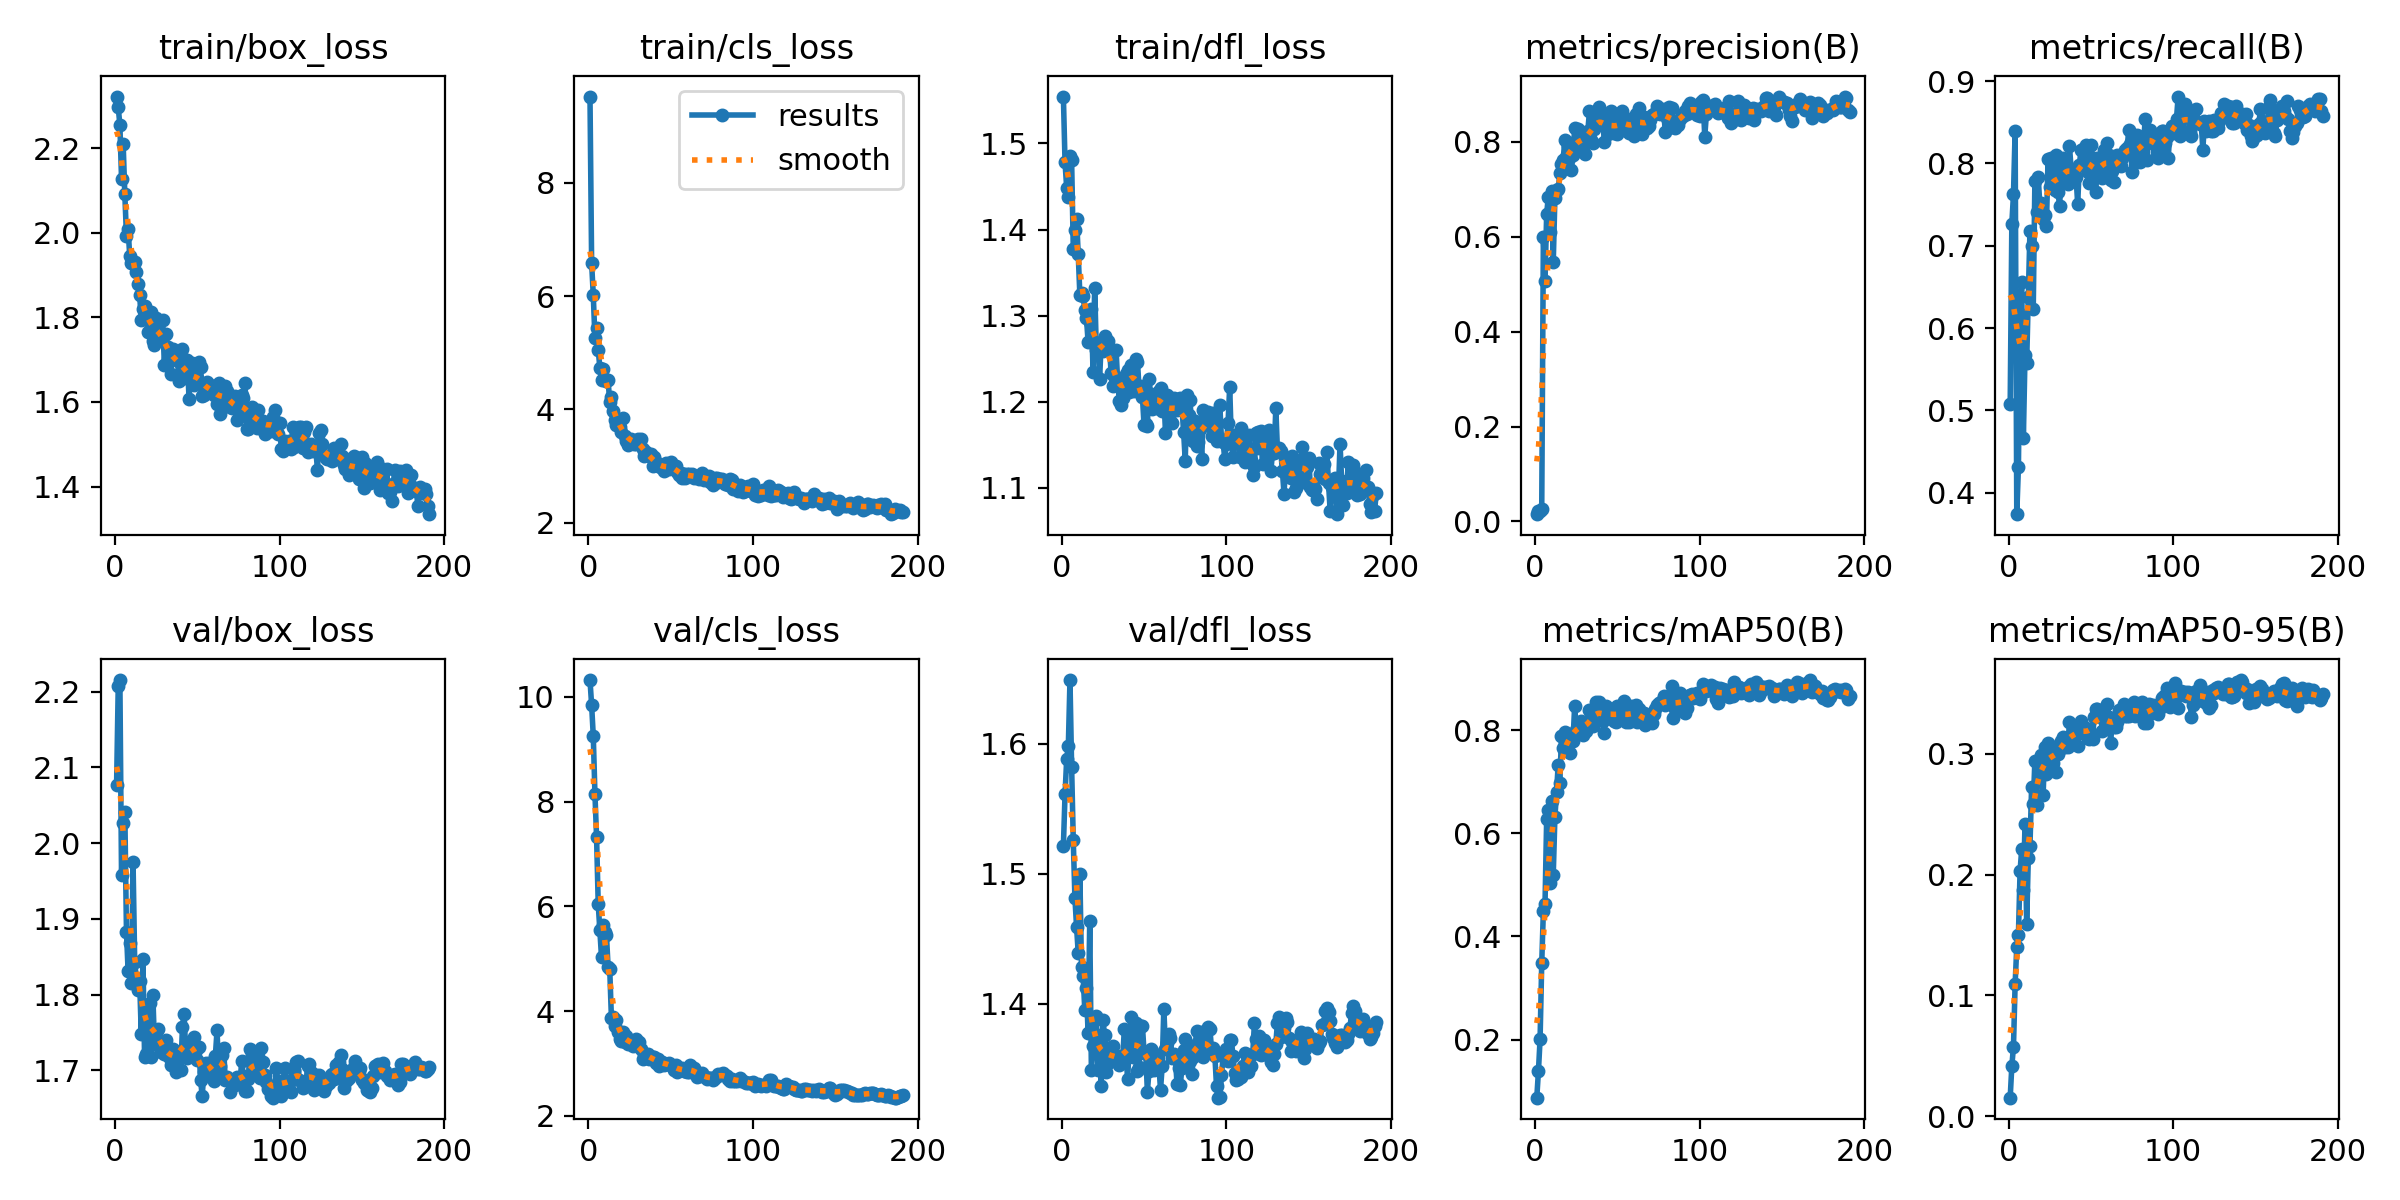

VISUALIZING: confusion_matrix.png


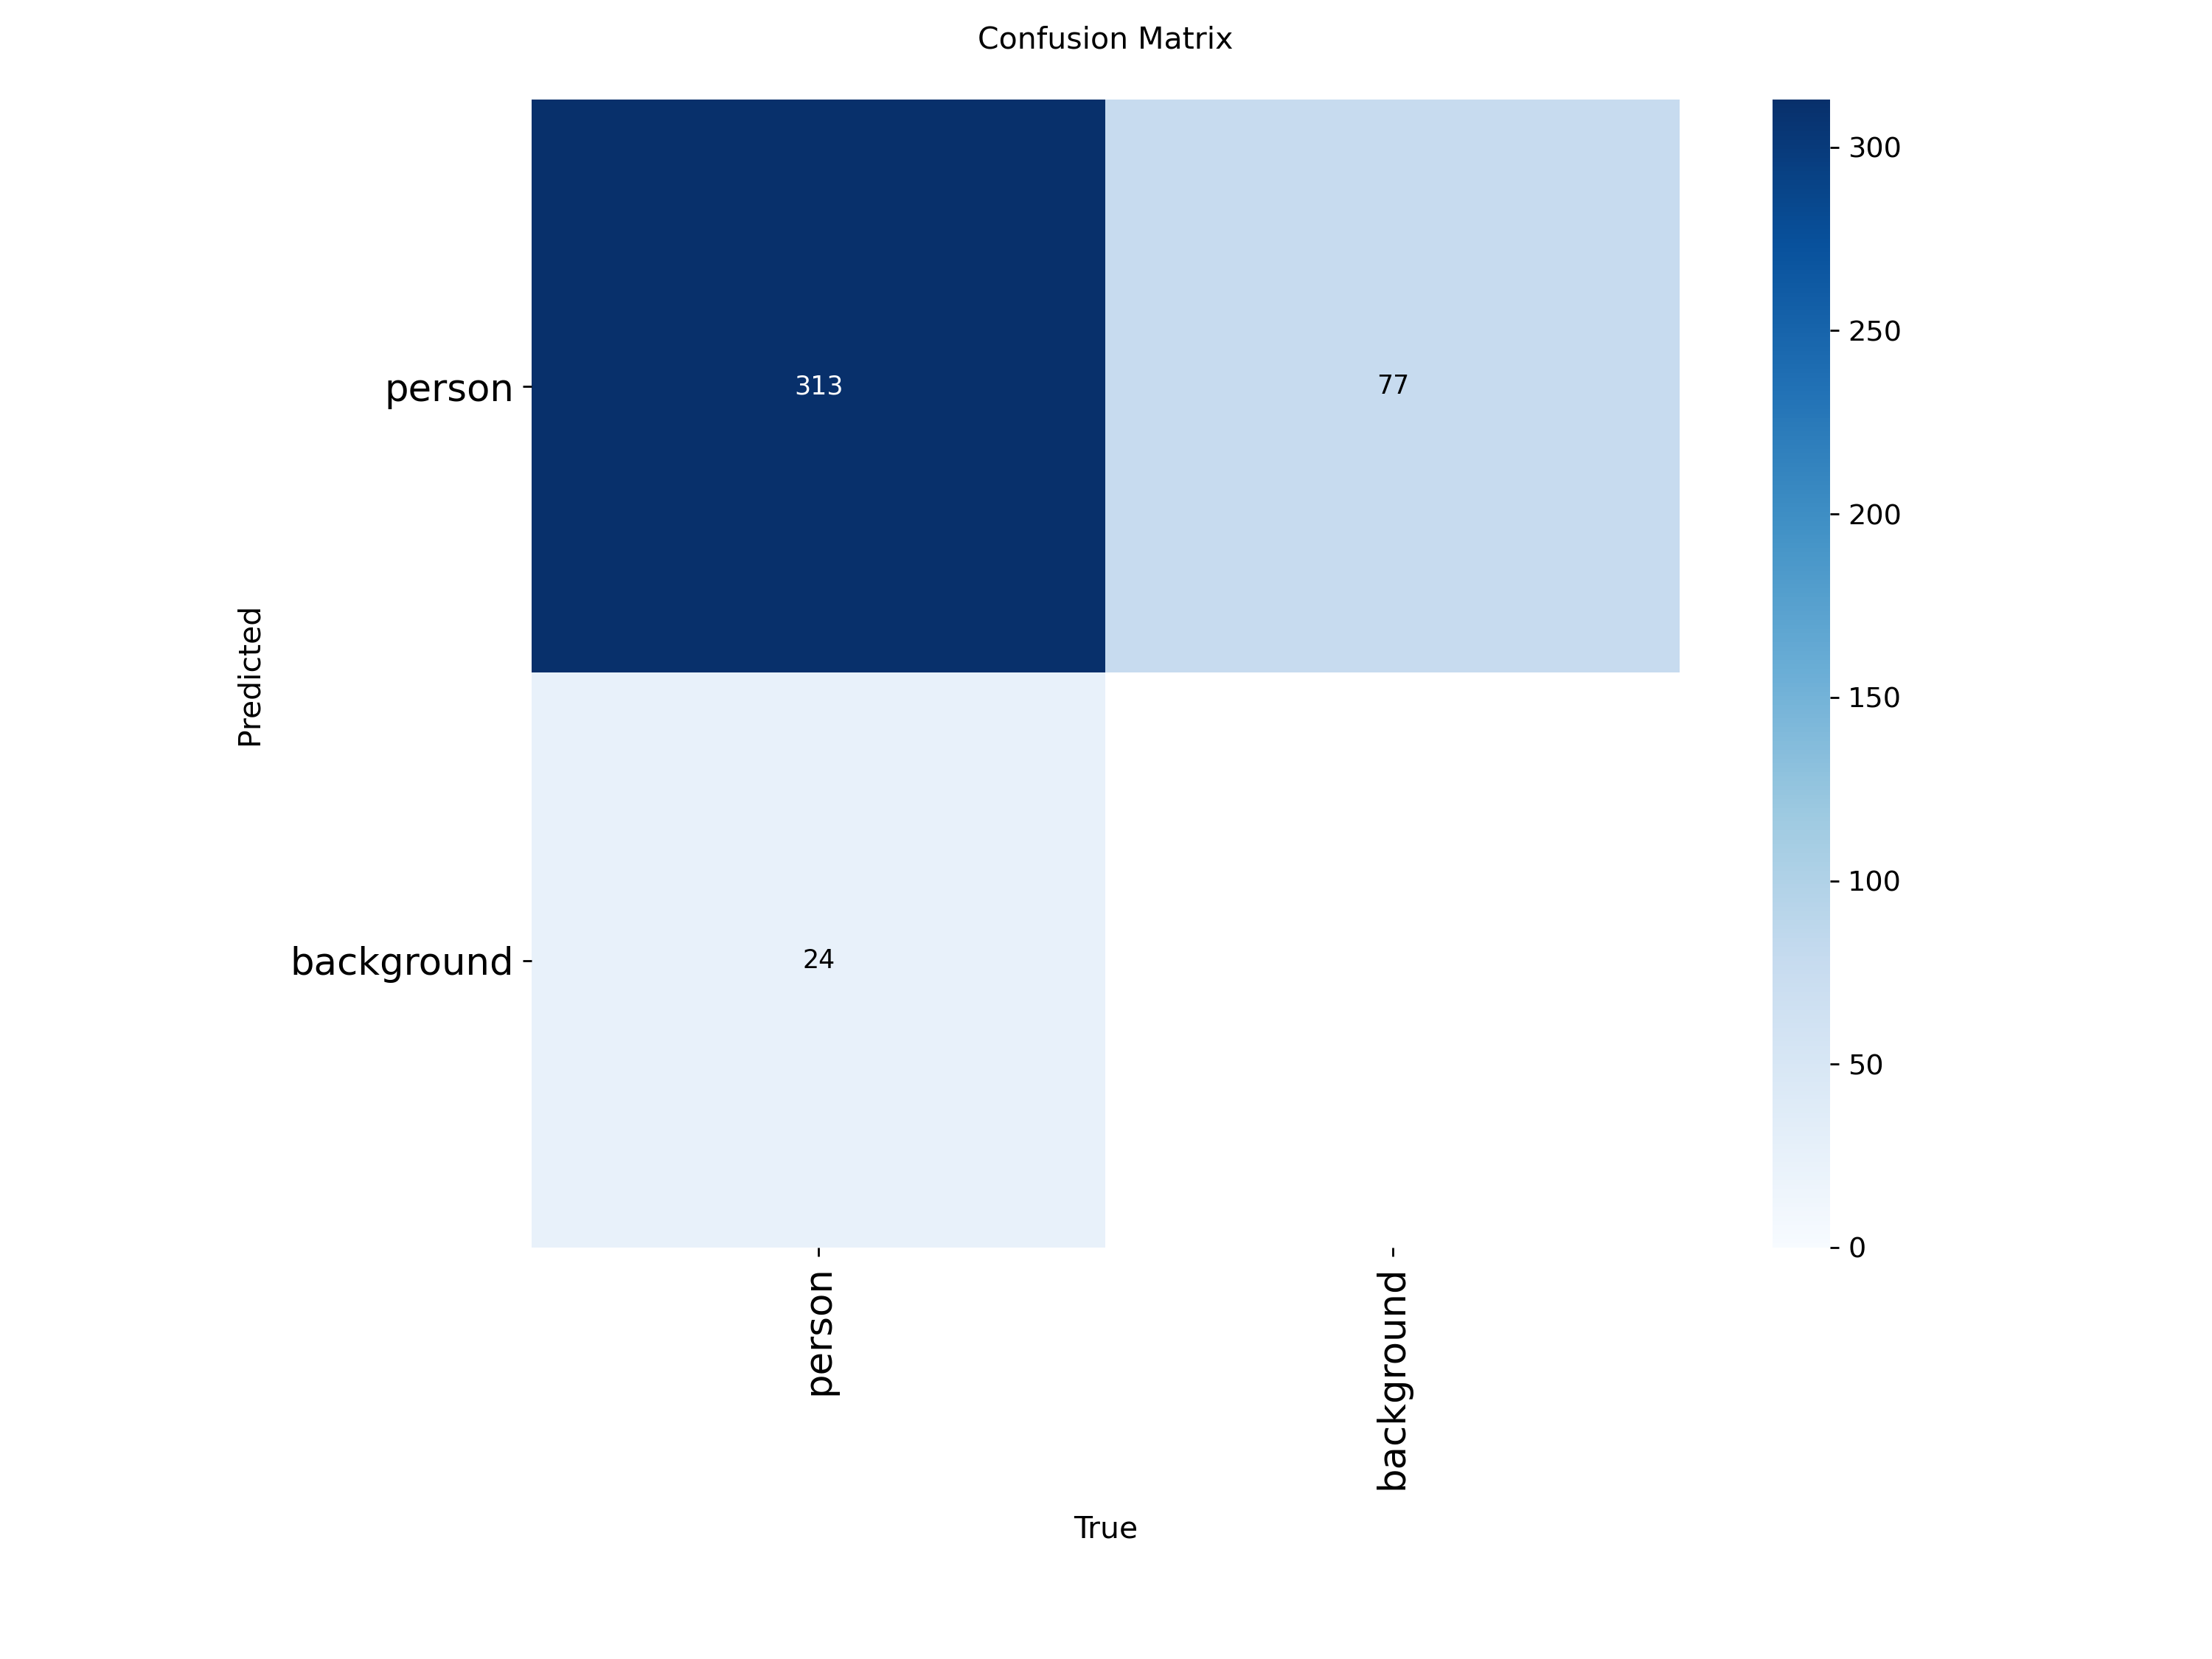

VISUALIZING: BoxF1_curve.png


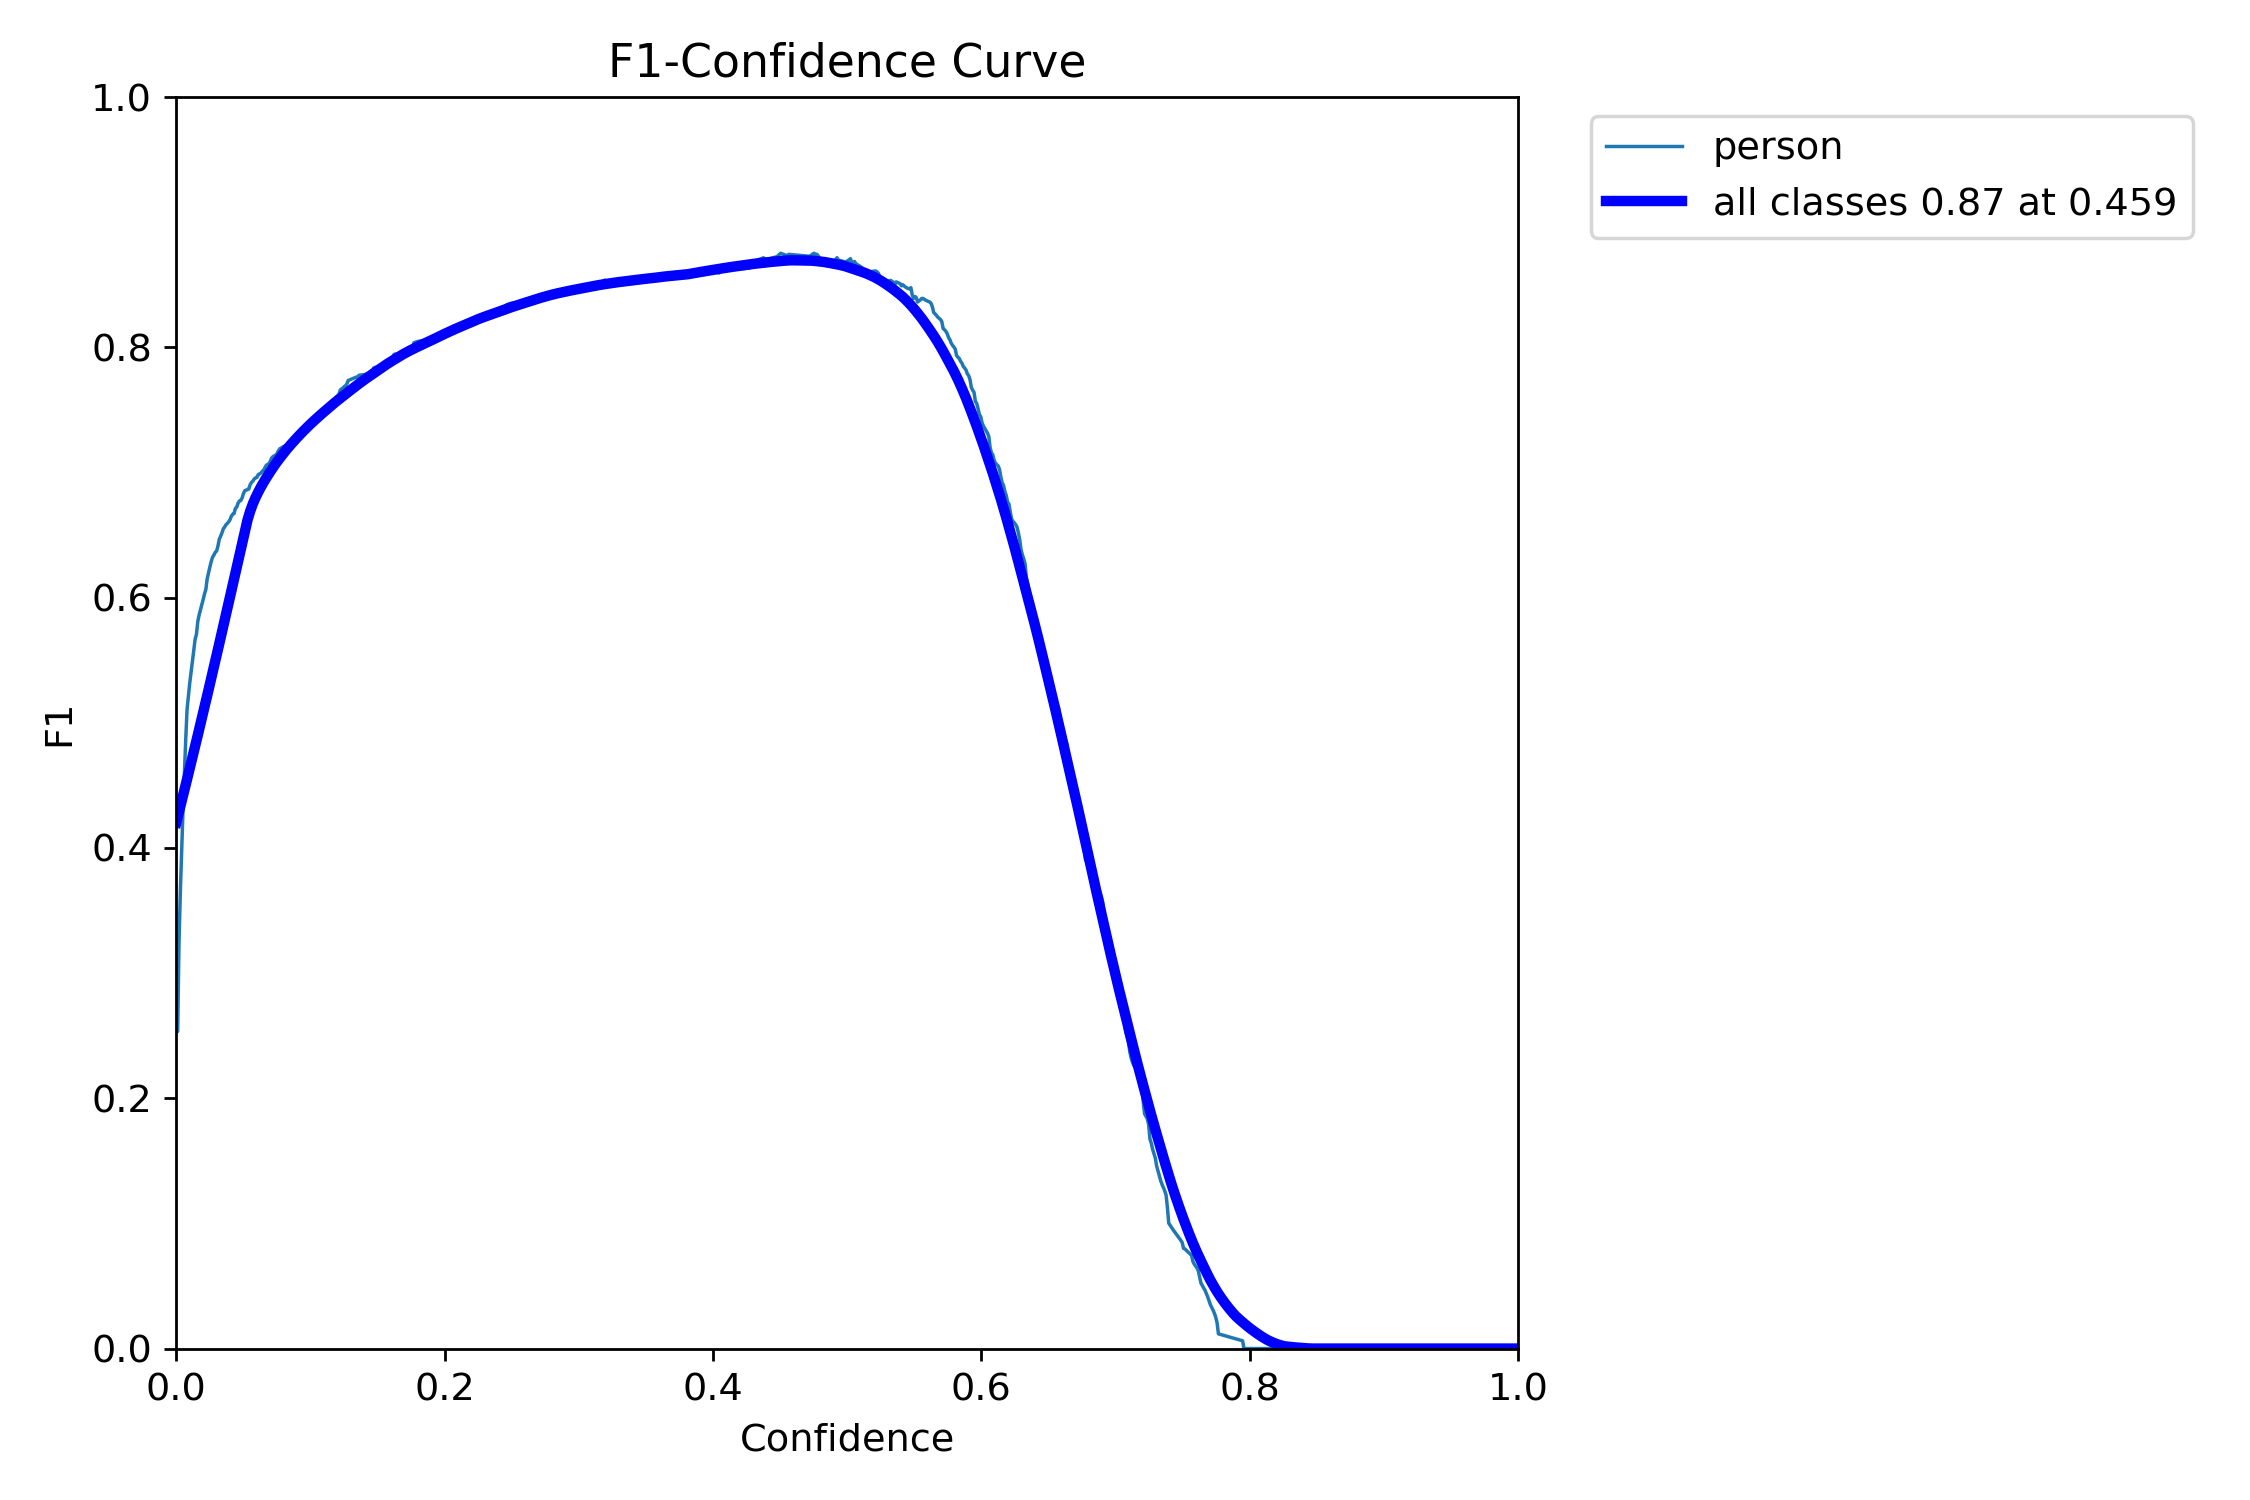

VISUALIZING: BoxPR_curve.png


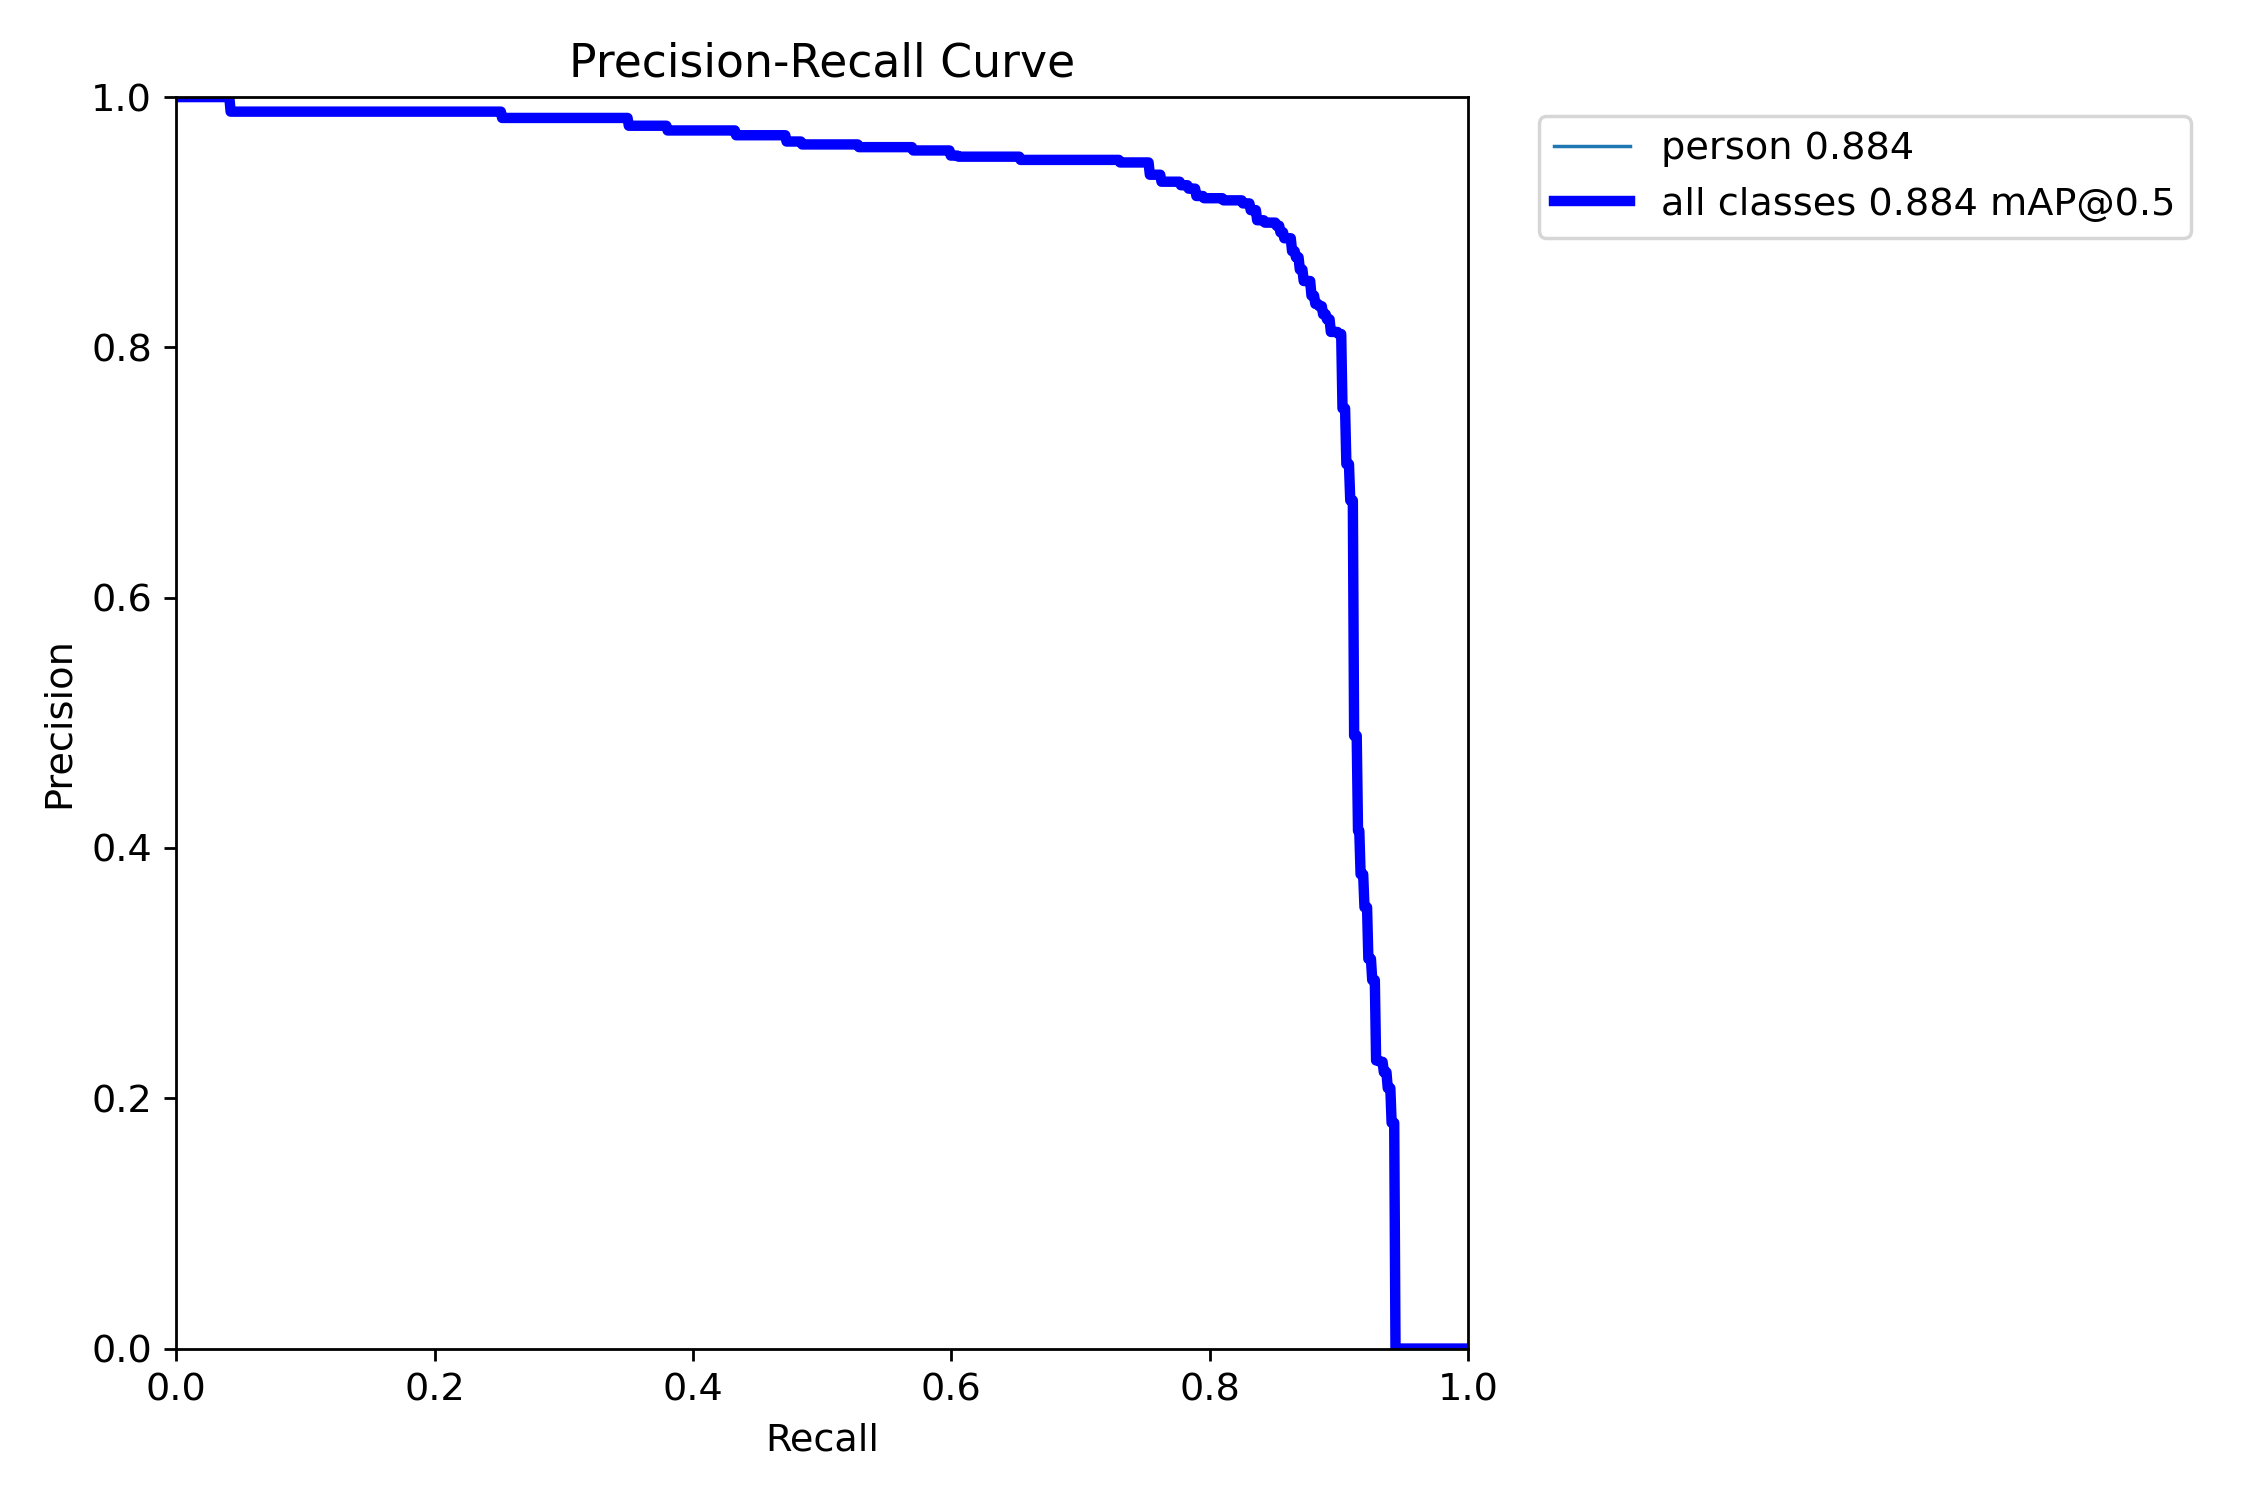

VISUALIZING: BoxP_curve.png


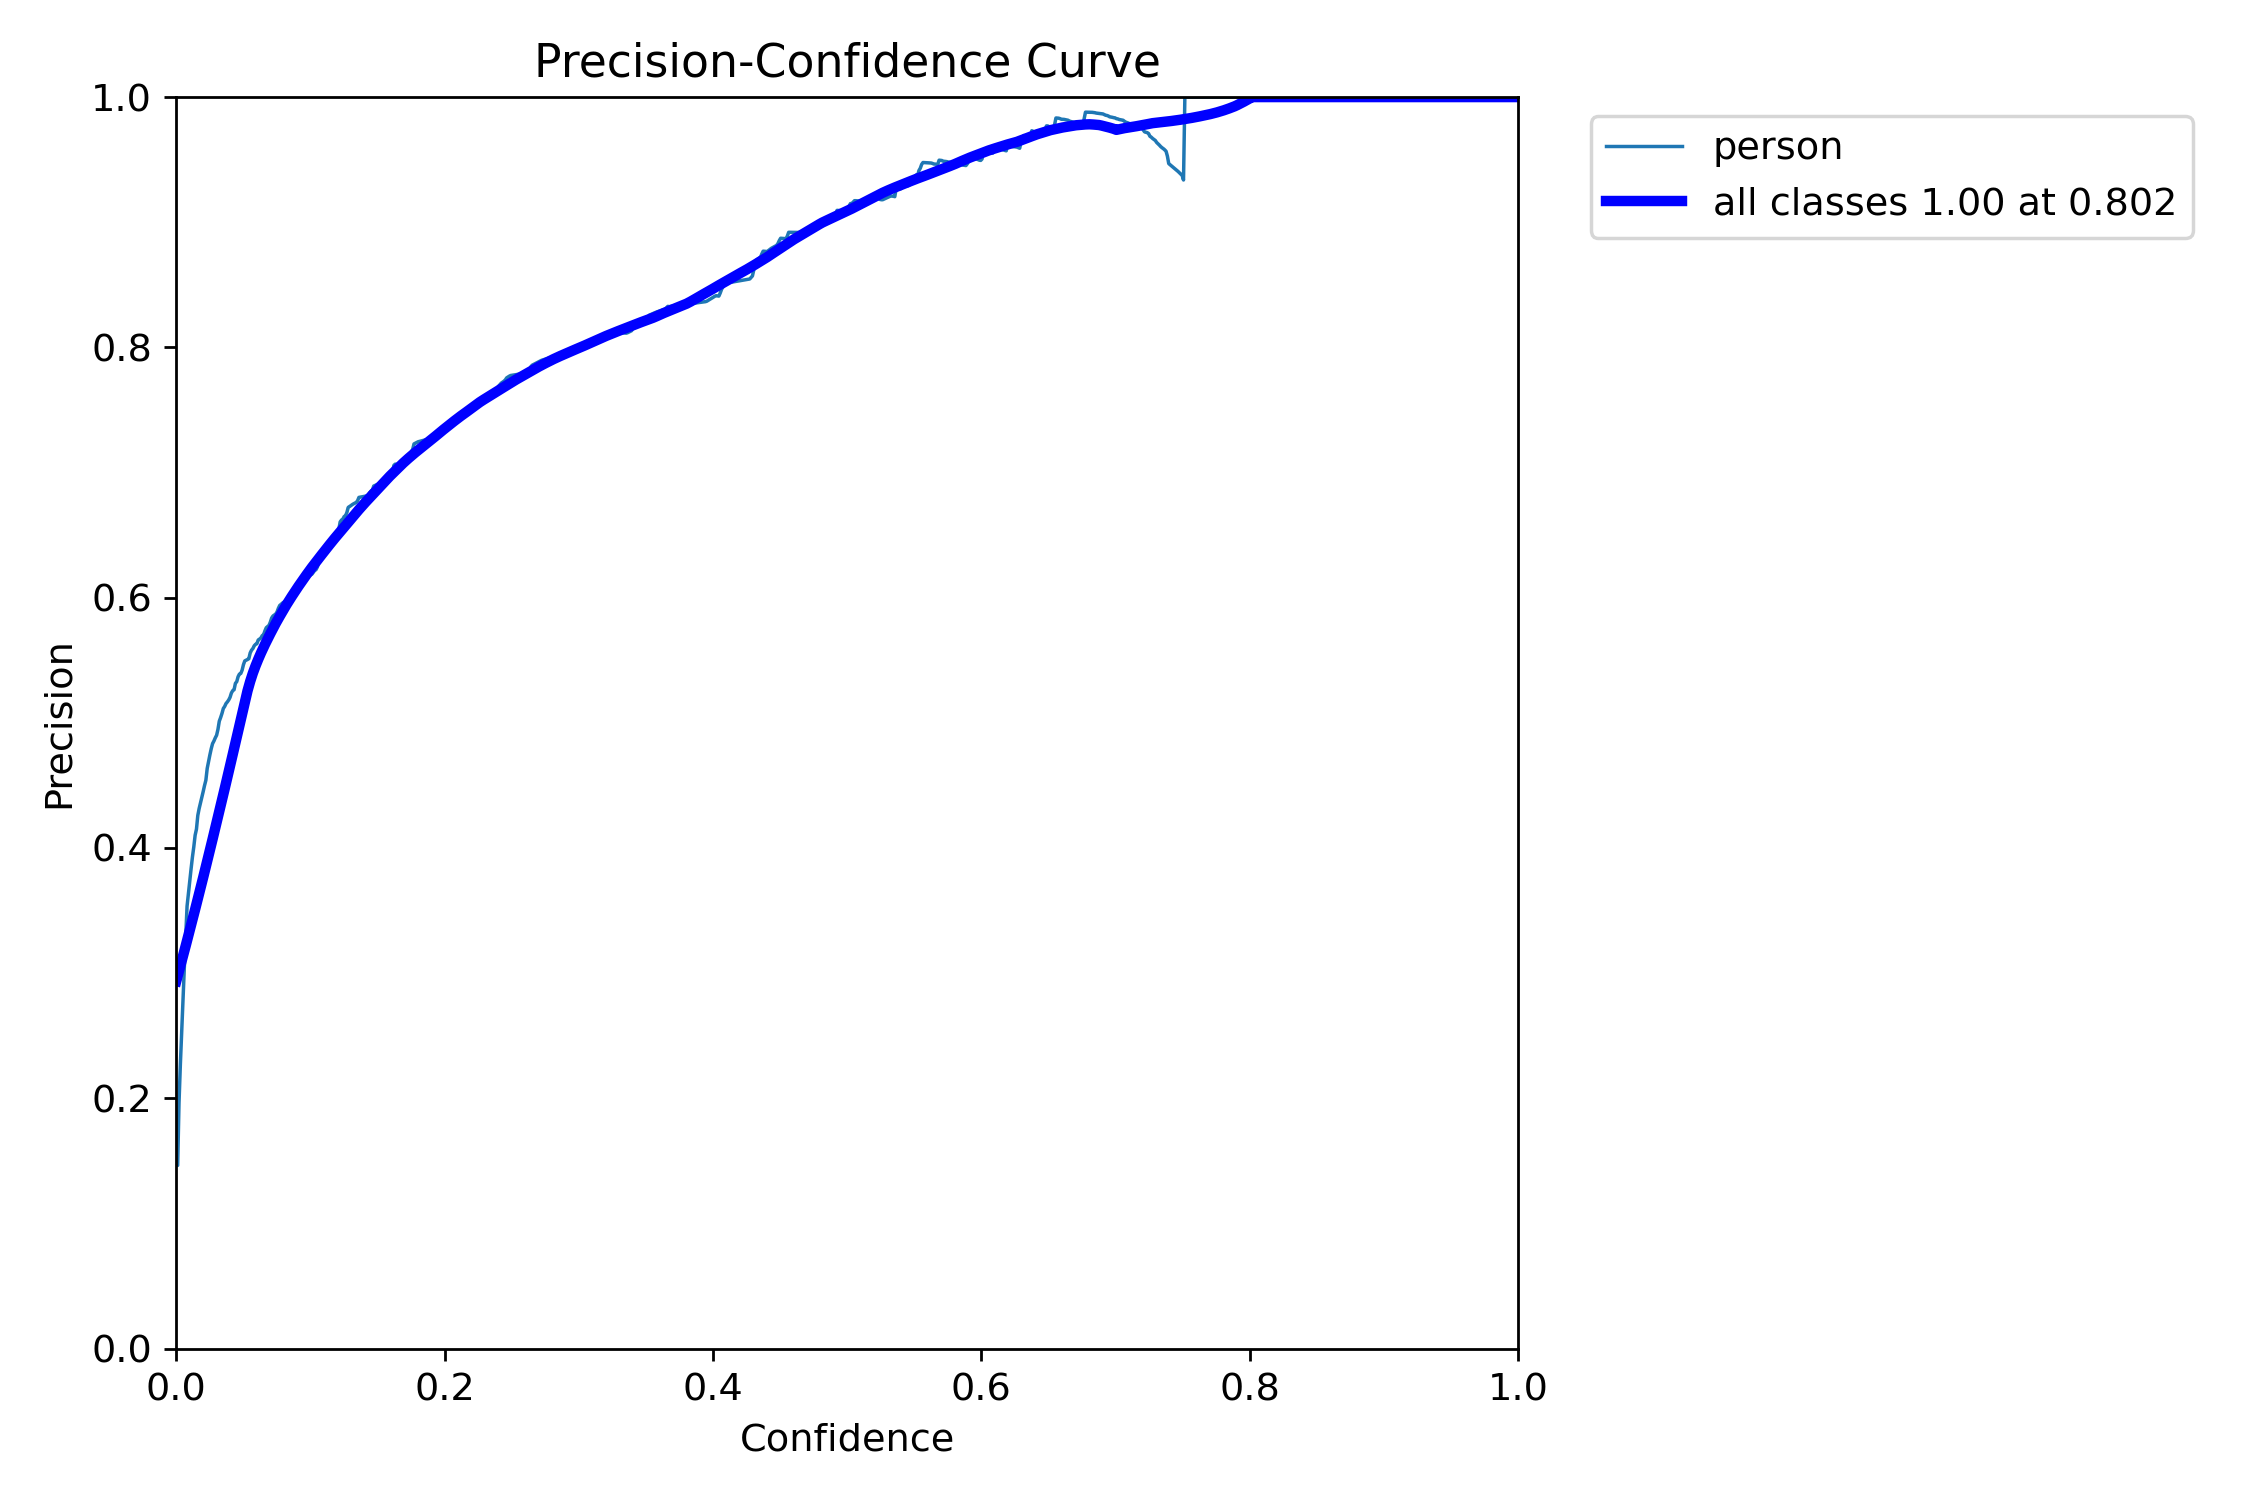

VISUALIZING: BoxR_curve.png


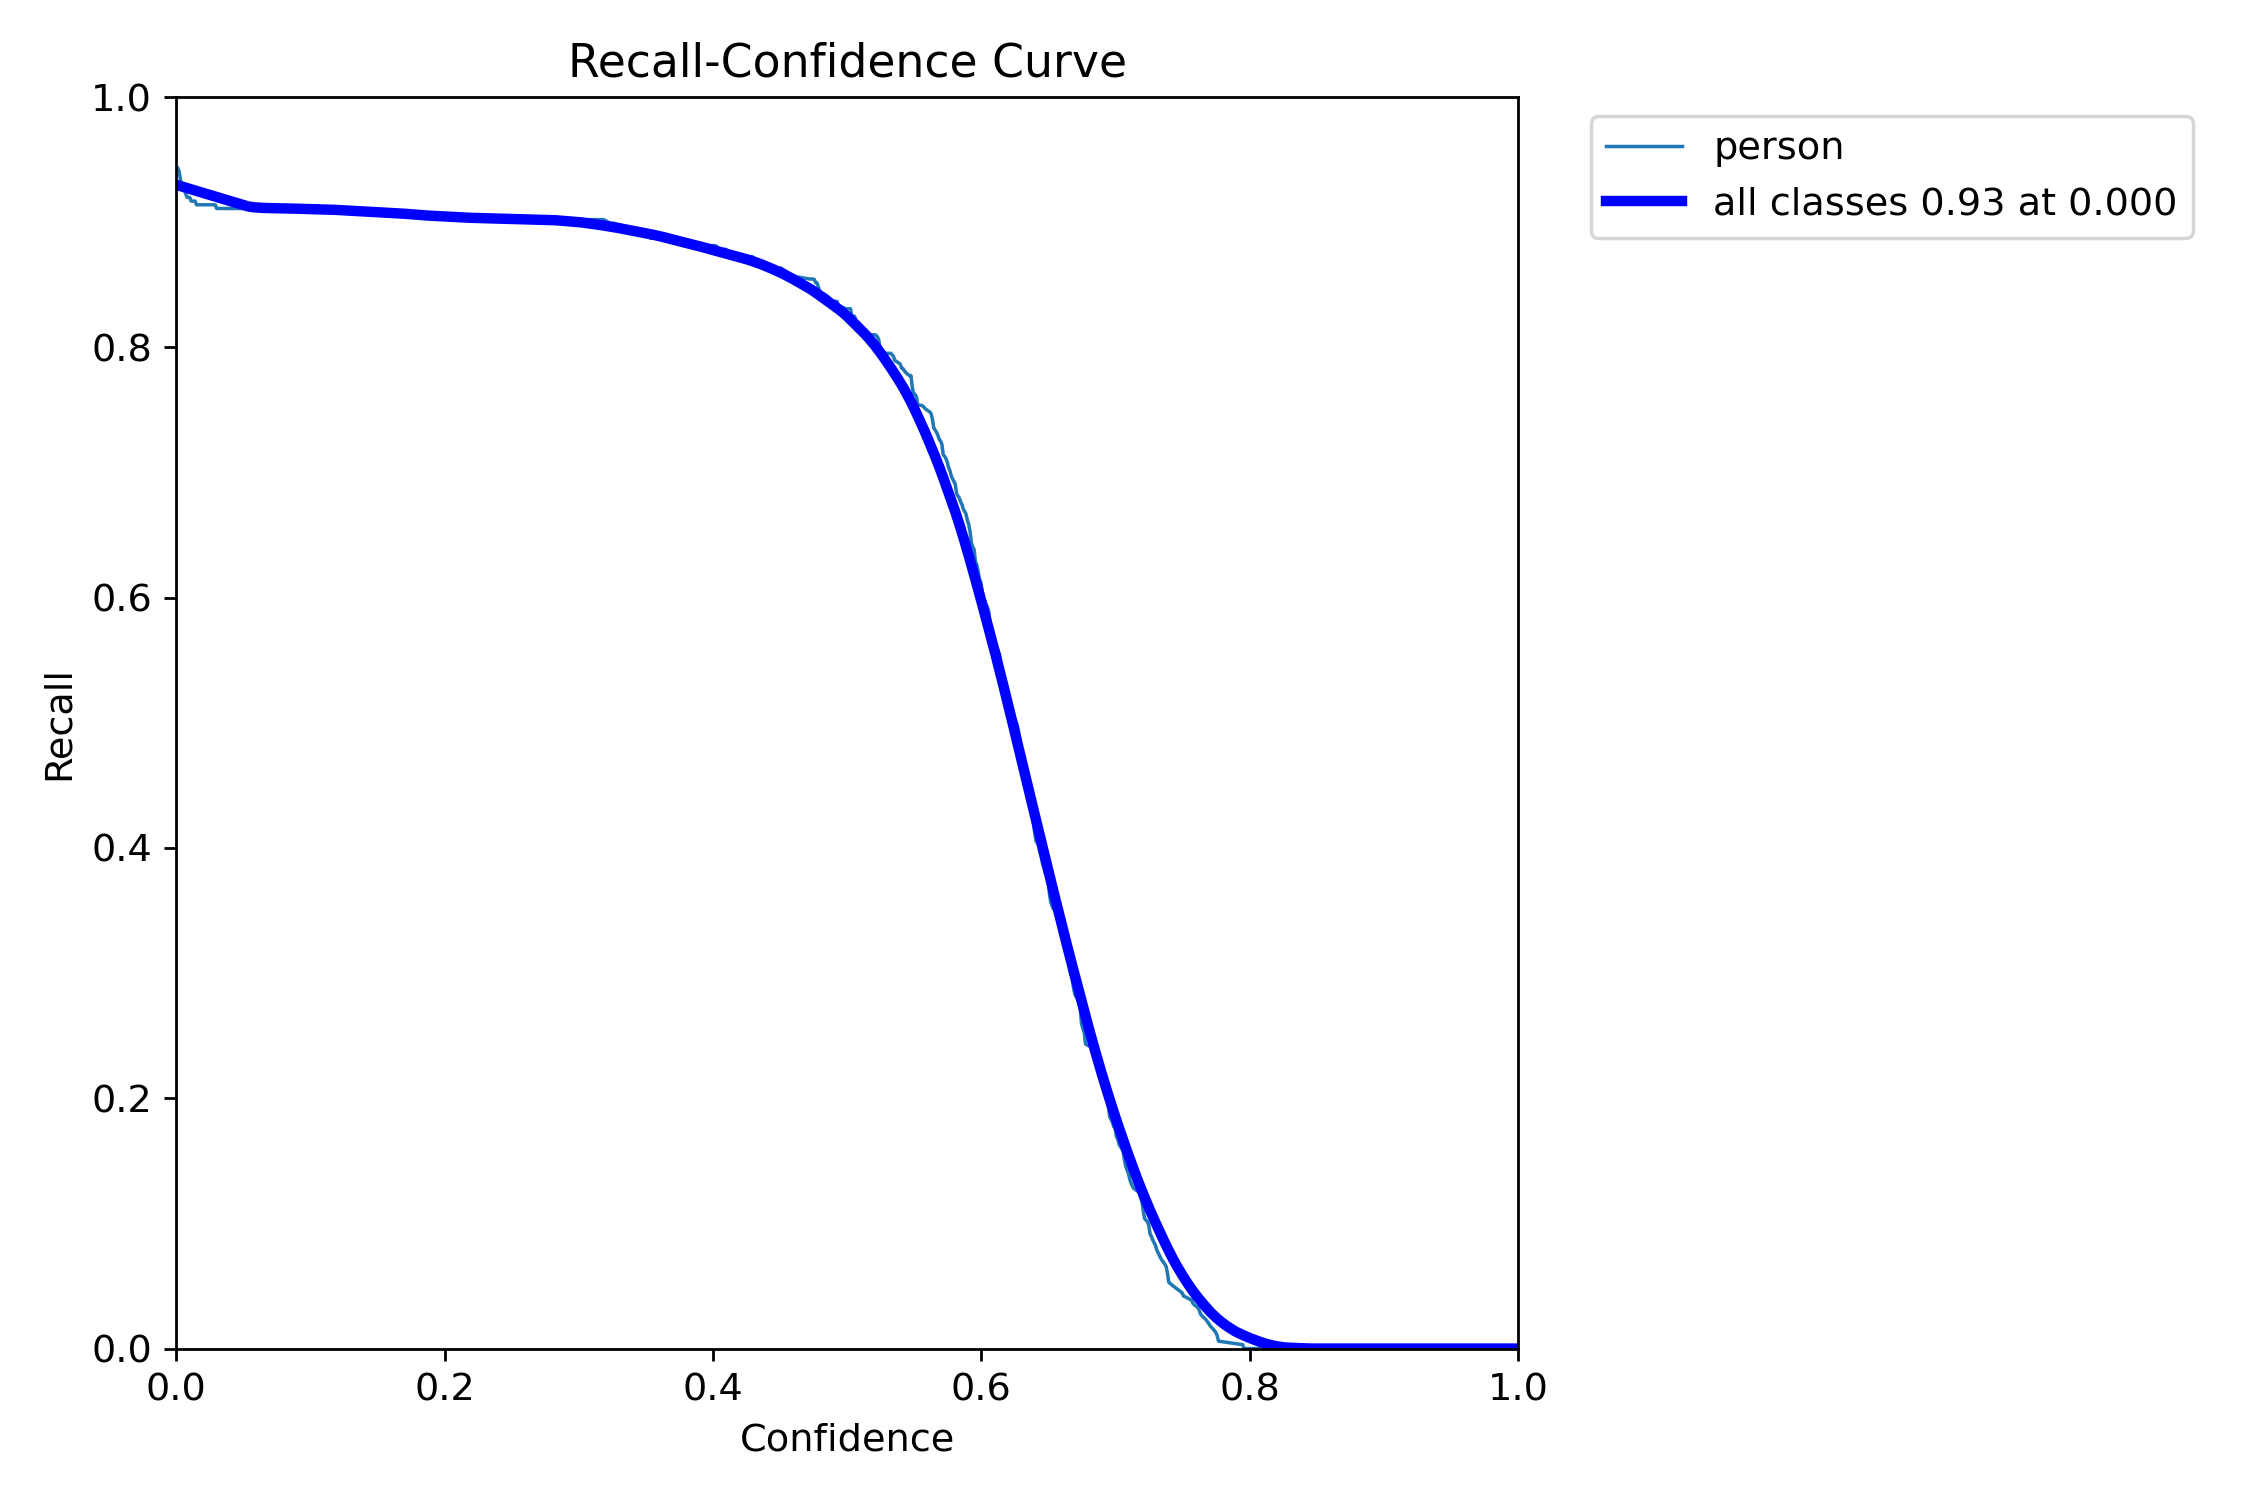

VISUALIZING: labels.jpg


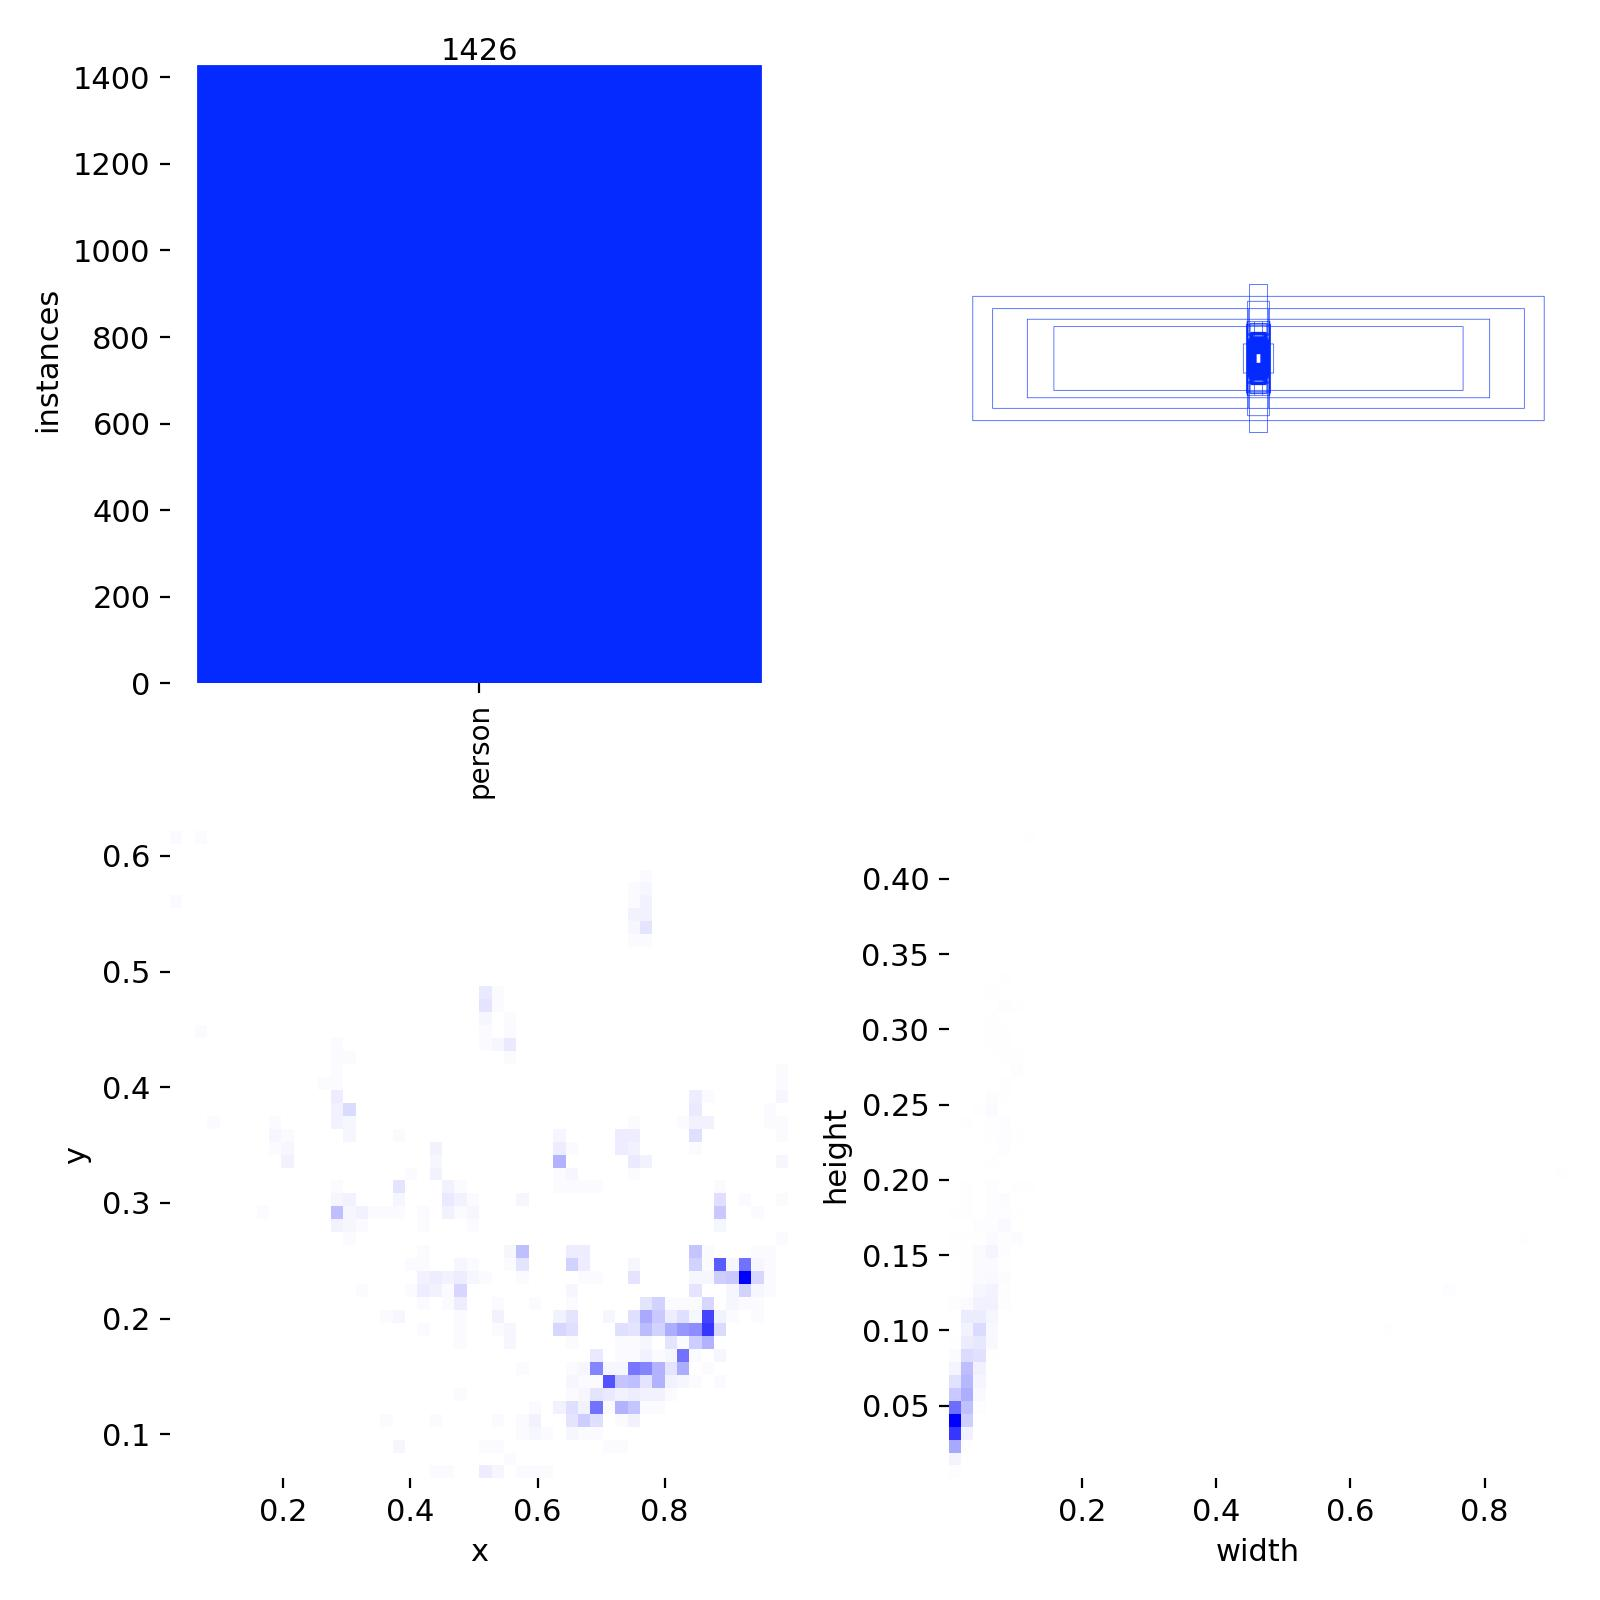

VISUALIZING: val_batch0_pred.jpg


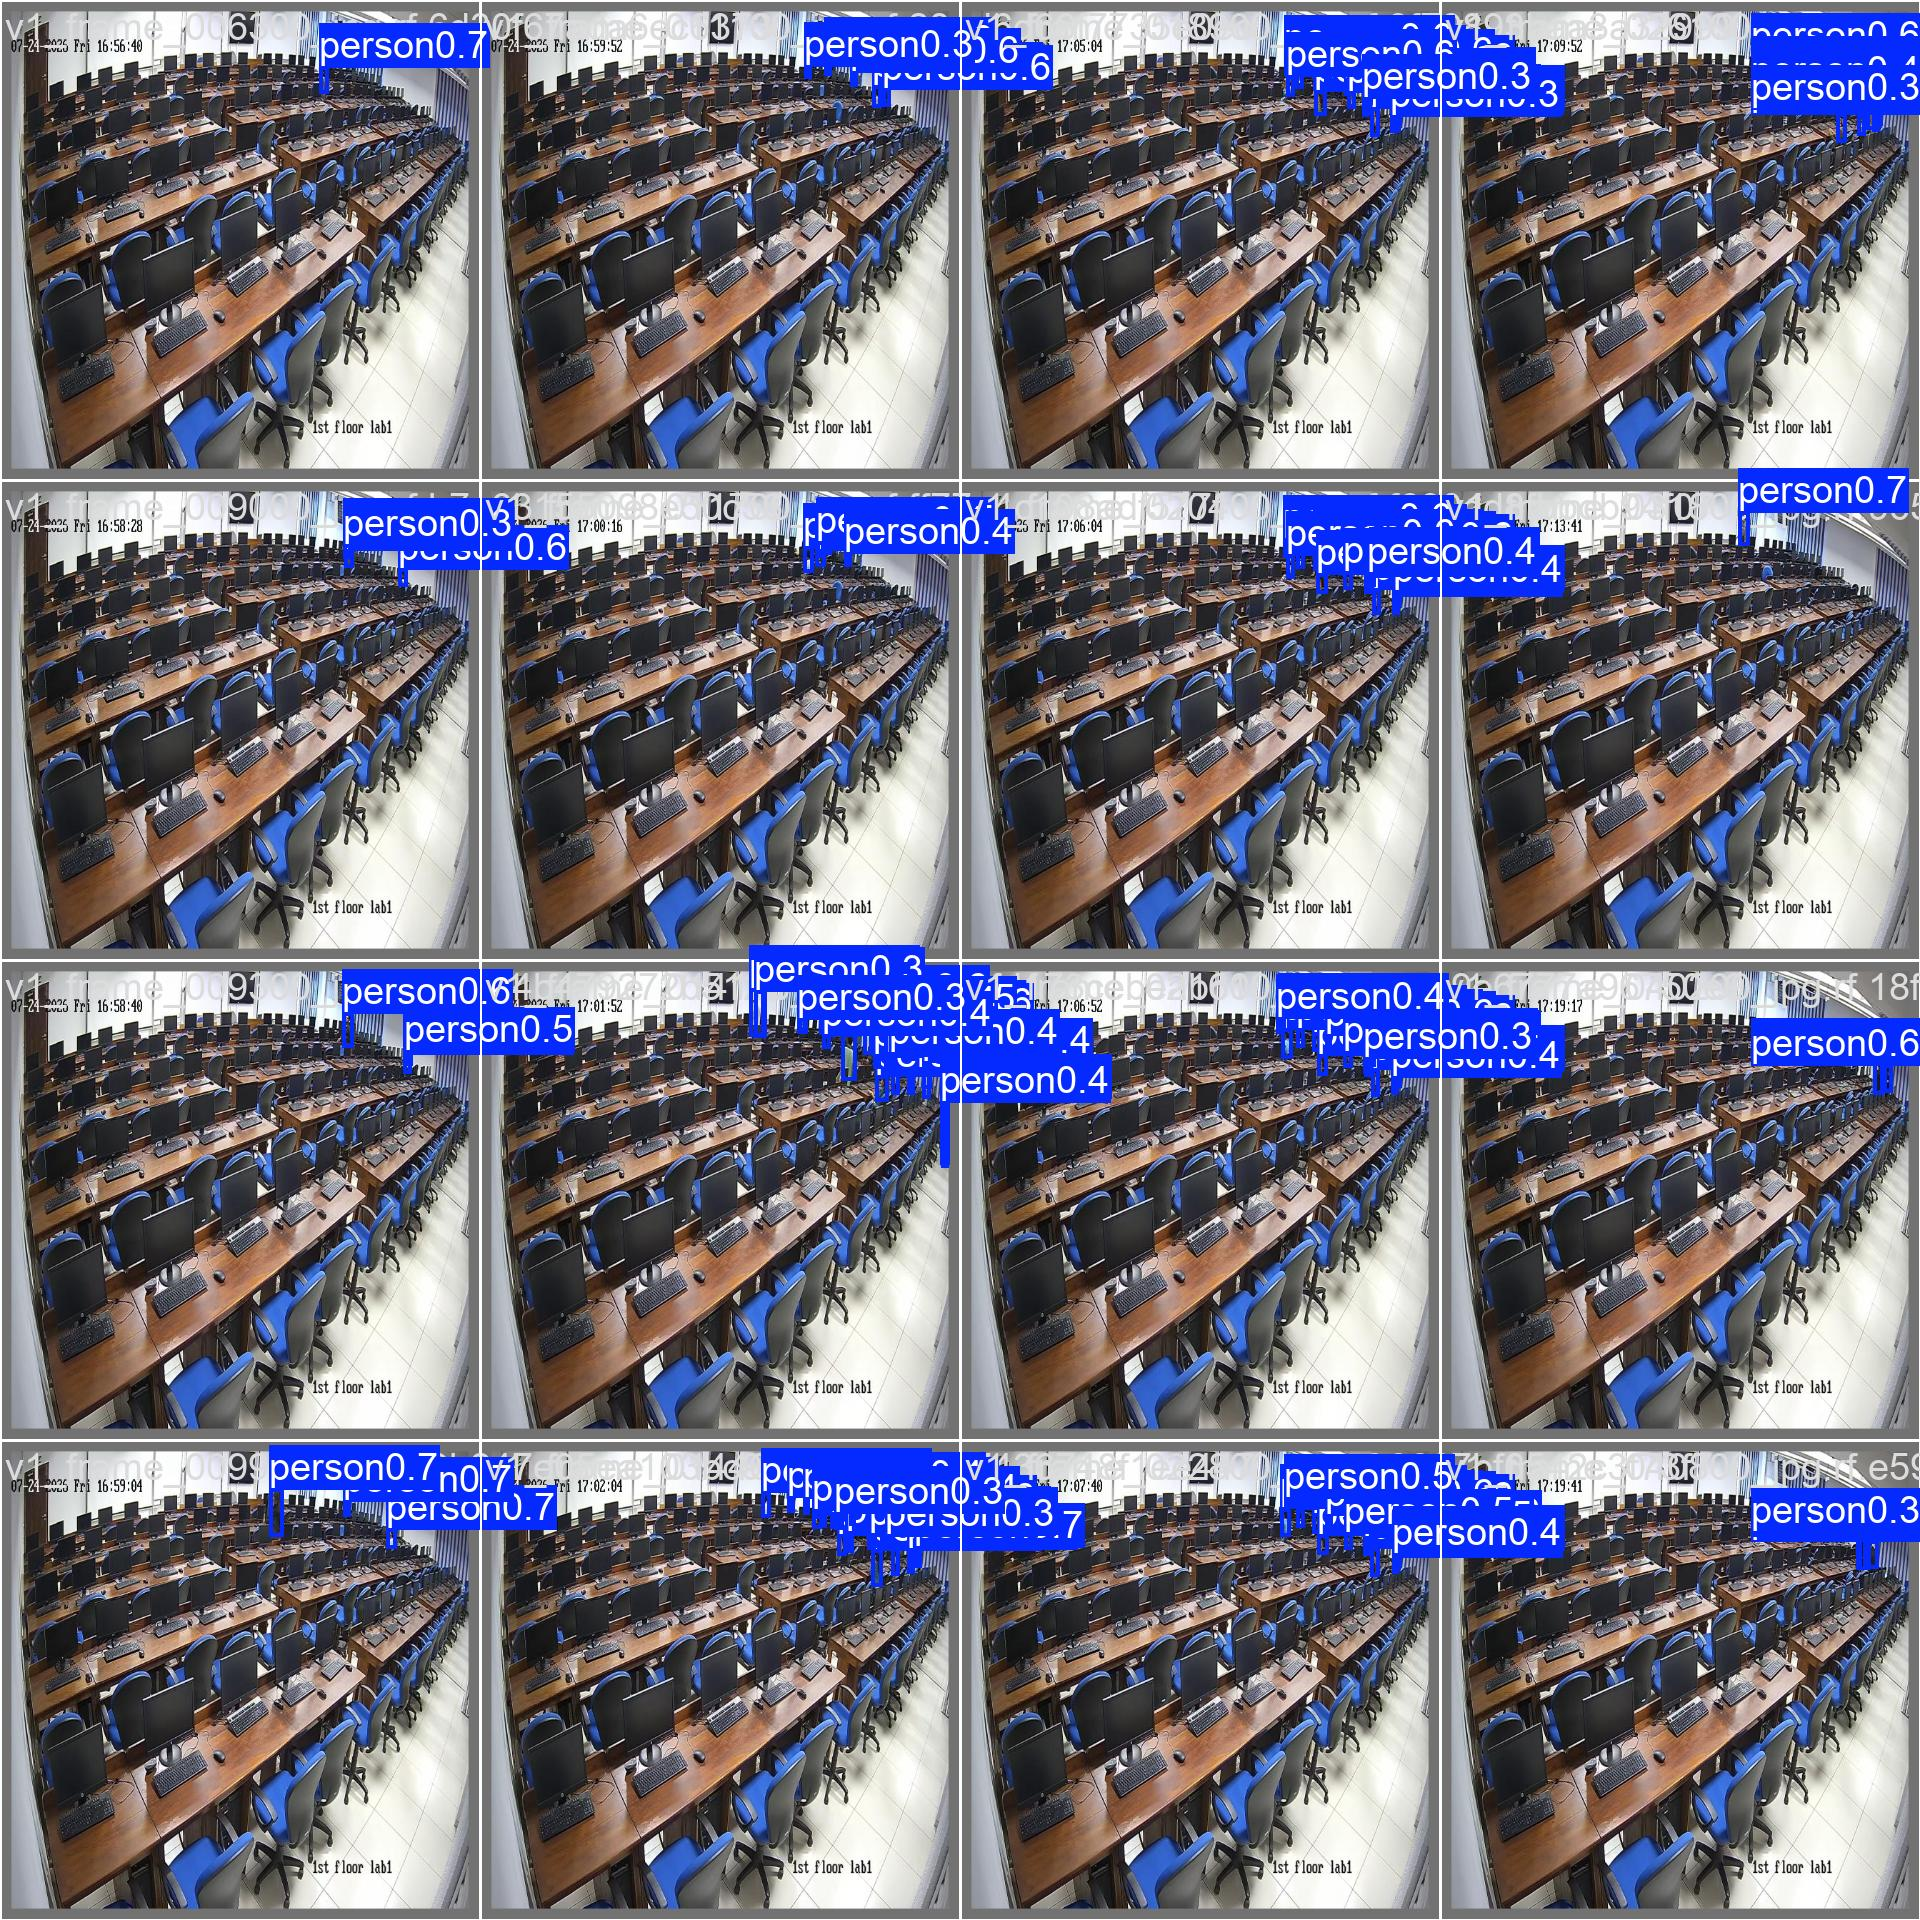

In [37]:
from IPython.display import Image, display

# Directory path containing final model evaluation artifacts
final_model_dir = "hpo_experiments/Final_Best_Model"

# List of key performance evaluation plots generated by YOLOv11
evaluation_plots = [
    "results.png",   # Loss curves & mAP50 progression over 200 epochs
    "confusion_matrix.png",  # Precision vs Recall confusion matrix
    "BoxF1_curve.png",   # F1-Score vs Confidence Threshold curve
    "BoxPR_curve.png",  # Precision-Recall curve
    "BoxP_curve.png",   # Precision-Confidence Curve
    "BoxR_curve.png",   # Recall-Confidence Curve
    "labels.jpg",  # Dataset Bounding Box Analytics
    "val_batch0_pred.jpg"  # Visual Detection Predictions on Classroom Test Images

]


for plot_name in evaluation_plots:
    plot_path = os.path.join(final_model_dir, plot_name)
    if os.path.exists(plot_path):
        print(f"VISUALIZING: {plot_name}")
        display(Image(filename=plot_path, width=800))
    else:
        print(f"Notice: Plot '{plot_name}' not found at path: {plot_path}")


## Model Evaluation Summary & Performance Analysis

- **mAP@50 Accuracy:** Reached **88.4% (0.884)**, demonstrating high overall student detection accuracy in the computer lab.
- **Optimal Confidence Threshold (`conf`):** Peak **F1-Score of 0.87 (87%)** achieved at **`conf = 0.46`** (recommended setting for production).
- **Detection Precision & Recall:** Achieved **93.0% Max Recall** (correctly detecting 313/337 student instances) and **100% Precision at `conf = 0.80`** (zero false alarms).
- **Overfitting Verification:** Training and validation loss curves decreased in parallel with zero divergence, confirming **zero overfitting**.
- **Recommended Deployment Settings:** Best inference performance achieved using **`conf=0.45`** and **`iou=0.60`**.
